In [1]:
from matplotlib import pyplot as plt
import pandas as pds
import numpy as np
import seaborn as sns


%matplotlib inline
%reload_ext autoreload
%autoreload 2

In [2]:
df = pds.read_csv("../data/AC597B1_ALL_LATEST.csv") # gonna use this dataset for both task 1 and task 2 ig
print(df.columns)
df_entities = df[(df["DIM_GEO_CODE_TYPE"] != "WHOREGION") & 
                (df["DIM_GEO_CODE_TYPE"] != "GLOBAL")]
#print(df["DIM_GEO_CODE_TYPE"].unique())
#df_countrynon = df[df["DIM_GEO_CODE_TYPE"] == "NATIONAL LIBERATION MOVEMENT"]
#print(df_country["GEO_NAME_SHORT"].unique().size)


Index(['IND_ID', 'IND_CODE', 'IND_UUID', 'IND_PER_CODE', 'DIM_TIME',
       'DIM_TIME_TYPE', 'DIM_GEO_CODE_M49', 'DIM_GEO_CODE_TYPE',
       'DIM_PUBLISH_STATE_CODE', 'IND_NAME', 'GEO_NAME_SHORT',
       'RATE_PER_100000_N', 'RATE_PER_100000_NL', 'RATE_PER_100000_NU'],
      dtype='object')


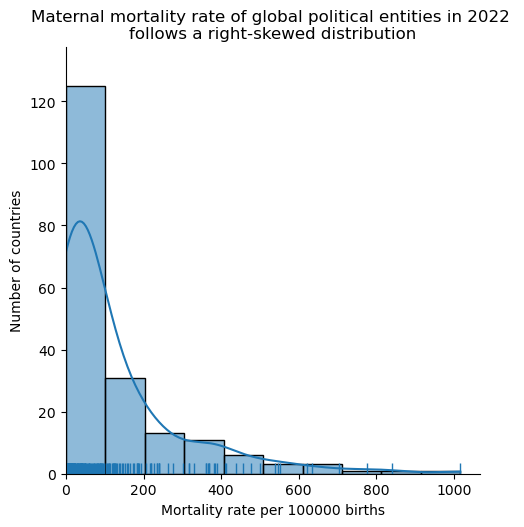

In [15]:
# Task 1
df_entities_2022 = df_entities[df_entities["DIM_TIME"] == 2022]

sns.displot(df_entities_2022["RATE_PER_100000_N"], 
            bins= 10, 
            rug = True, 
            kde = True).set(xlim=(0),
                            title = "Maternal mortality rate of global political entities in 2022 \nfollows a right-skewed distribution",
                            xlabel = "Mortality rate per 100000 births",
                            ylabel = "Number of countries") # Change later
                                                                                         

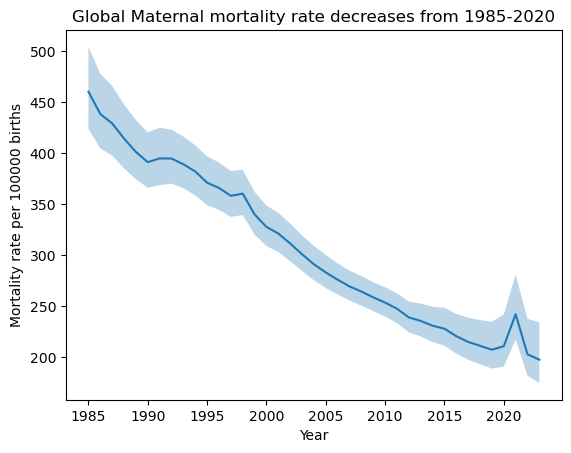

In [16]:
# Task 2
df_world = df[df["DIM_GEO_CODE_TYPE"] == "GLOBAL"].sort_values("DIM_TIME")

xy_values = df_world[["RATE_PER_100000_N", "DIM_TIME"]]
y_values_upper = np.array(df_world["RATE_PER_100000_NU"].values)
y_values_lower = np.array(df_world["RATE_PER_100000_NL"].values)


sns.lineplot(xy_values, x = "DIM_TIME", y= "RATE_PER_100000_N").set(title = "Global Maternal mortality rate decreases from 1985-2020",
                                                                    xlabel = "Year",
                                                                    ylabel = "Mortality rate per 100000 births")
plt.fill_between(xy_values["DIM_TIME"].values,  y_values_lower, y_values_upper, alpha = 0.3)